# **PREDICCION DE APROBACION DE PRESTAMOS** - Con Aprendizaje Automático
## Por Carlos A. Ugarte
**Caso educativo | Datos completamente sintéticos | Python y clasificación supervisada**

**Alcance:** se predice una *decisión de aprobación simulada* (`Y`/`N`), **no** el incumplimiento ni la solvencia crediticia. Ningún resultado habilita decisiones financieras reales.

**Flujo:** simulación → auditoría → exploración → separación estratificada → preprocesamiento sin fuga → comparación con líneas base → SVC → evaluación por clase → análisis de umbrales → exportación.

**Diccionario:** se conservan los nombres originales de columnas para facilitar interoperabilidad, mientras explicaciones, gráficos y archivos se presentan en castellano.

## 1. Configuración y reproducibilidad
Ejecutar el notebook desde `notebooks/` o desde la raíz del repositorio. Las rutas se resuelven buscando `README.md`; se crean carpetas de salida. El entorno se instala mediante `requirements.txt`. La semilla fija hace repetible la simulación, aunque versiones distintas de bibliotecas pueden modificar ligeramente métricas.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, balanced_accuracy_score,
                             f1_score, precision_recall_curve, average_precision_score,
                             brier_score_loss, RocCurveDisplay)
SEED, N = 42, 614
rng = np.random.default_rng(SEED)
raiz = Path.cwd().resolve()
if not (raiz / 'README.md').exists():
    if (raiz.parent / 'README.md').exists(): raiz = raiz.parent
    else: raise FileNotFoundError('Ejecutar desde la raíz del repositorio o desde notebooks/.')
DATA, OUTPUTS, FIGURES = (raiz/'data', raiz/'outputs', raiz/'figures')
for carpeta in (DATA, OUTPUTS, FIGURES): carpeta.mkdir(exist_ok=True)
print('Raíz:', raiz)

Raíz: C:\Mis Documentos\My_Career_Strategy\12_MisProyectos\11-Prediccion_Aprobacion_Prestamos


## 2. Simulación de solicitudes
**Regla generadora:** Semilla 42, 614 solicitudes, 13 columnas y siete variables con ausencias. La variable objetivo es sorteada con probabilidades artificiales según historial, carga de pago aproximada y zona semiurbana. Esto introduce patrones *por construcción*, no evidencia de una institución financiera.

In [2]:
gender = rng.choice(['Male','Female'], N, p=[.79,.21])
married = rng.choice(['Yes','No'], N, p=[.65,.35])
dependents = rng.choice(['0','1','2','3+'], N, p=[.56,.17,.17,.10])
education = rng.choice(['Graduate','Not Graduate'], N, p=[.78,.22])
self_employed = rng.choice(['No','Yes'], N, p=[.86,.14])
property_area = rng.choice(['Rural','Semiurban','Urban'], N, p=[.29,.38,.33])
applicant_income = np.maximum(150, np.round(rng.lognormal(np.log(3900), .62, N))).astype(int)
coapplicant_income = np.where(rng.random(N) < .44, 0, np.round(rng.lognormal(np.log(1700), .65, N))).astype(int)
loan_amount = np.clip(np.round(25 + .018 * (applicant_income + coapplicant_income) + rng.normal(0, 52, N)), 9, 700)
loan_term = rng.choice([12.,36.,60.,84.,120.,180.,240.,300.,360.,480.], N,
                       p=[.005,.005,.01,.01,.025,.035,.035,.05,.80,.025])
credit_history = rng.choice([0.,1.], N, p=[.16,.84])
# Regla didáctica: probabilidad asociada a historial, capacidad de pago y monto solicitado.
monthly_income = applicant_income + coapplicant_income
payment_proxy = loan_amount * 1000 / np.maximum(loan_term, 12)
burden = payment_proxy / np.maximum(monthly_income, 1)
logit = -0.35 + 2.1 * credit_history - 1.9 * burden + .22 * (property_area == 'Semiurban')
prob_approval = 1 / (1 + np.exp(-logit))
loan_status = np.where(rng.random(N) < prob_approval, 'Y', 'N')

df = pd.DataFrame({'Loan_ID':[f'LP{i:06d}' for i in range(1002,1002+N)],
 'Gender':gender,'Married':married,'Dependents':dependents,'Education':education,
 'Self_Employed':self_employed,'ApplicantIncome':applicant_income,
 'CoapplicantIncome':coapplicant_income,'LoanAmount':loan_amount.astype(float),
 'Loan_Amount_Term':loan_term,'Credit_History':credit_history,
 'Property_Area':property_area,'Loan_Status':loan_status})
# Reproducimos tasas de ausencia aproximadas del ejemplo original.
for col, count in {'Gender':13,'Married':3,'Dependents':15,'Self_Employed':32,
                   'LoanAmount':22,'Loan_Amount_Term':14,'Credit_History':50}.items():
    idx = rng.choice(N, size=count, replace=False)
    df.loc[idx,col] = np.nan
assert df.shape == (614,13)
df.to_csv(DATA / 'solicitudes_prestamo_sinteticas.csv', index=False)
print('Solicitudes:',df.shape, '| Etiquetas:',df.Loan_Status.value_counts().to_dict())
display(df.head())

Solicitudes: (614, 13) | Etiquetas: {'Y': 455, 'N': 159}


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,NaN,3+,Graduate,No,9268,0,129.0,360.0,1.0,Rural,Y
1,LP001003,Male,No,0,Not Graduate,No,7108,6145,313.0,120.0,1.0,Urban,Y
2,LP001004,Female,No,0,Graduate,No,17462,0,277.0,360.0,1.0,Urban,Y
3,LP001005,Male,Yes,1,Graduate,No,1648,1175,67.0,360.0,1.0,Urban,Y
4,LP001006,Male,Yes,0,Graduate,Yes,9632,1629,226.0,360.0,1.0,Urban,Y


## 3. Auditoría de calidad y diccionario
`Loan_ID`: identificador artificial, excluido del modelo. `Gender`, `Married`, `Dependents`, `Education`, `Self_Employed`, `Property_Area`: atributos categóricos. `ApplicantIncome`, `CoapplicantIncome`: ingresos ficticios. `LoanAmount`: monto simulado en miles de unidades. `Loan_Amount_Term`: plazo simulado. `Credit_History`: indicador artificial 0/1. `Loan_Status`: aprobación sintética `Y` o `N`.

Los atributos personales se mantienen para reproducir el ejemplo original, **sin avalar su uso operativo**. Se comprueban dominios, unicidad, nulos y proporción de clases.

In [3]:
assert df.shape == (614,13)
assert df.Loan_ID.is_unique
assert set(df.Loan_Status.unique()) == {'N','Y'}
assert (df[['ApplicantIncome','CoapplicantIncome']].ge(0)).all().all()
assert df['LoanAmount'].dropna().gt(0).all()
assert df['Credit_History'].dropna().isin([0,1]).all()
calidad = pd.DataFrame({'nulos':df.isna().sum(), 'porcentaje_nulos':df.isna().mean()*100})
display(calidad.loc[calidad.nulos.gt(0)].round(2))
display(df.Loan_Status.value_counts().rename_axis('estado').reset_index(name='solicitudes'))

,nulos,porcentaje_nulos
Gender,13,2.12
Married,3,0.49
Dependents,15,2.44
Self_Employed,32,5.21
LoanAmount,22,3.58
Loan_Amount_Term,14,2.28
Credit_History,50,8.14


,estado,solicitudes
0,Y,455
1,N,159


## 4. Análisis exploratorio
La distribución de clases permite identificar desbalance; los gráficos de ingresos y montos muestran asimetrías y valores extremos. Son asociaciones descriptivas sobre una simulación, **no** factores causales ni evidencias de discriminación o riesgo.

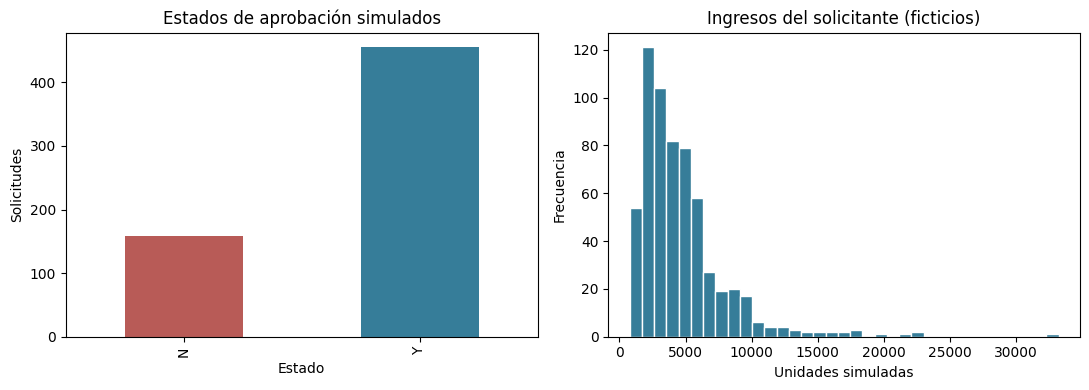

In [4]:
fig, ax=plt.subplots(1,2,figsize=(11,4))
df.Loan_Status.value_counts().reindex(['N','Y']).plot.bar(ax=ax[0], color=['#B85B57','#367D99'])
ax[0].set(title='Estados de aprobación simulados',xlabel='Estado',ylabel='Solicitudes')
ax[1].hist(df.ApplicantIncome,bins=35,color='#367D99',edgecolor='white')
ax[1].set(title='Ingresos del solicitante (ficticios)',xlabel='Unidades simuladas',ylabel='Frecuencia')
plt.tight_layout();plt.savefig(FIGURES/'exploracion.png',dpi=160);plt.show()

## 5. División de datos y preprocesamiento sin fuga
Se separa el **20 % para prueba final**, con estratificación. Medianas, modas, escalado y codificación se ajustan **solo con entrenamiento** dentro de `Pipeline`. No se utiliza `Loan_ID` ni la variable objetivo como predictor.

In [5]:
X=df.drop(columns=['Loan_ID','Loan_Status']); y=df.Loan_Status
numericas=['ApplicantIncome','CoapplicantIncome','LoanAmount','Loan_Amount_Term','Credit_History']
categoricas=['Gender','Married','Dependents','Education','Self_Employed','Property_Area']
def preparar():
    return ColumnTransformer([
        ('numericas',Pipeline([('imputacion',SimpleImputer(strategy='median')),('escalado',StandardScaler())]),numericas),
        ('categoricas',Pipeline([('imputacion',SimpleImputer(strategy='most_frequent')),('codificacion',OneHotEncoder(handle_unknown='ignore'))]),categoricas)
    ])
X_ent,X_pru,y_ent,y_pru=train_test_split(X,y,test_size=.20,stratify=y,random_state=SEED)
print('Entrenamiento:',len(X_ent),'| Prueba:',len(X_pru))

Entrenamiento: 491 | Prueba: 123


## 6. Modelos de referencia y validación cruzada
Se contrastan `DummyClassifier` (clase mayoritaria), regresión logística y SVC RBF. La validación cruzada estratificada de cinco pliegues se realiza **únicamente en entrenamiento**. Se informan accuracy, balanced accuracy y F1 macro; este último evita que una clase mayoritaria domine la evaluación.

In [6]:
modelos={
 'Mayoritaria':Pipeline([('preparacion',preparar()),('clasificador',DummyClassifier(strategy='most_frequent'))]),
 'Regresión logística':Pipeline([('preparacion',preparar()),('clasificador',LogisticRegression(max_iter=1500,random_state=SEED))]),
 'SVC RBF':Pipeline([('preparacion',preparar()),('clasificador',SVC(kernel='rbf',probability=True,random_state=SEED))])
}
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
filas=[]
for nombre, modelo_cv in modelos.items():
    r=cross_validate(modelo_cv,X_ent,y_ent,cv=cv,scoring={'exactitud':'accuracy','balanceada':'balanced_accuracy','f1_macro':'f1_macro'},n_jobs=1)
    filas.append({'Modelo':nombre,**{k:round(r['test_'+k].mean(),3) for k in ['exactitud','balanceada','f1_macro']}})
comparacion=pd.DataFrame(filas)
display(comparacion)

,Modelo,exactitud,balanceada,f1_macro
0,Mayoritaria,0.741,0.500,0.426
1,Regresión logística,0.780,0.636,0.652
2,SVC RBF,0.780,0.634,0.649


## 7. Ajuste y evaluación final de SVC
Se conserva el SVC RBF del proyecto original para permitir una comparación conceptual. La prueba final no se usa para elegir hiperparámetros. La matriz de confusión usa filas = etiquetas sintéticas y columnas = predicciones. **Recall N** es crítico para entender cuántos rechazos simulados no son detectados.

,valor
accuracy,0.8293
balanced_accuracy,0.6820
f1_macro,0.7144
roc_auc,0.7933
average_precision_Y,0.8782
brier_Y,0.1418


              precision    recall  f1-score   support

           N       0.92      0.38      0.53        32
           Y       0.82      0.99      0.90        91

    accuracy                           0.83       123
   macro avg       0.87      0.68      0.71       123
weighted avg       0.85      0.83      0.80       123



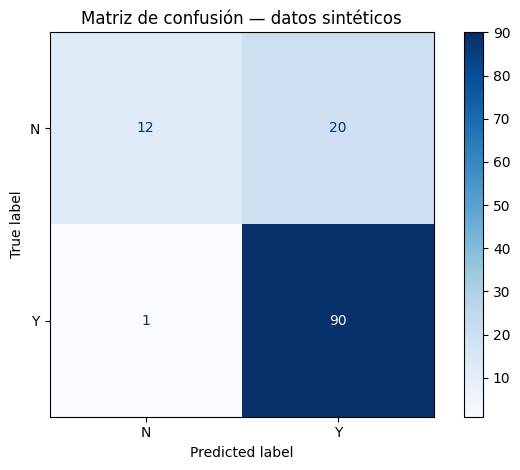

In [7]:
modelo=modelos['SVC RBF'];modelo.fit(X_ent,y_ent)
pred=modelo.predict(X_pru)
proba=modelo.predict_proba(X_pru)[:,list(modelo.classes_).index('Y')]
metricas={'accuracy':accuracy_score(y_pru,pred),'balanced_accuracy':balanced_accuracy_score(y_pru,pred),
          'f1_macro':f1_score(y_pru,pred,average='macro'),'roc_auc':roc_auc_score(y_pru.eq('Y'),proba),
          'average_precision_Y':average_precision_score(y_pru.eq('Y'),proba),
          'brier_Y':brier_score_loss(y_pru.eq('Y'),proba)}
display(pd.DataFrame([metricas]).T.rename(columns={0:'valor'}).round(4))
print(classification_report(y_pru,pred,labels=['N','Y'],zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_pru,pred,labels=['N','Y'],cmap='Blues')
plt.title('Matriz de confusión — datos sintéticos');plt.tight_layout()
plt.savefig(FIGURES/'matriz_confusion.png',dpi=160);plt.show()

## 8. Curva ROC, umbrales y calibración
El ROC AUC evalúa discriminación; Brier resume error cuadrático de probabilidad, **sin demostrar por sí solo calibración adecuada**. Se exploran umbrales sobre la probabilidad de `Y` exclusivamente como análisis de sensibilidad. **No se recomienda ningún umbral operativo** sin costos de error, equidad y validación externa.

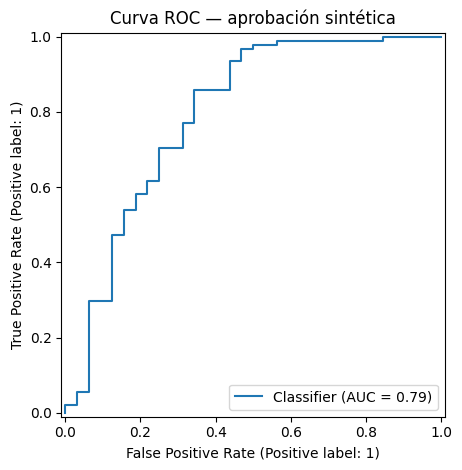

,umbral_Y,recall_N,recall_Y,f1_macro
0,0.3,0.000,1.000,0.425
1,0.4,0.281,0.989,0.655
2,0.5,0.344,0.989,0.696
3,0.6,0.438,0.978,0.741
4,0.7,0.531,0.956,0.772


In [8]:
RocCurveDisplay.from_predictions(y_pru.eq('Y').astype(int),proba)
plt.title('Curva ROC — aprobación sintética');plt.tight_layout();plt.savefig(FIGURES/'curva_roc.png',dpi=160);plt.show()
filas=[]
for umbral in [0.3,0.4,0.5,0.6,0.7]:
    p=np.where(proba>=umbral,'Y','N')
    cm=confusion_matrix(y_pru,p,labels=['N','Y'])
    filas.append({'umbral_Y':umbral,'recall_N':cm[0,0]/cm[0].sum(),'recall_Y':cm[1,1]/cm[1].sum(),
                  'f1_macro':f1_score(y_pru,p,average='macro')})
display(pd.DataFrame(filas).round(3))

## 9. Exportación y controles de integridad
Se exportan los datos sintéticos, predicciones del conjunto de prueba, métricas y gráficos. El identificador se recupera por índice, sin incorporarlo al modelo. La columna `probabilidad_Y_modelo` es una estimación del clasificador sobre etiquetas artificiales, **no una probabilidad real de aprobación**.

In [9]:
resultado=X_pru.copy()
resultado.insert(0,'Loan_ID',df.loc[X_pru.index,'Loan_ID'].to_numpy())
resultado['estado_sintetico']=y_pru.to_numpy()
resultado['estado_predicho']=pred
resultado['probabilidad_Y_modelo']=proba
assert len(resultado)==len(X_pru) and resultado.Loan_ID.is_unique
assert resultado.probabilidad_Y_modelo.between(0,1).all()
resultado.to_csv(OUTPUTS/'predicciones_prueba_sinteticas.csv',index=False)
pd.DataFrame([metricas]).to_csv(OUTPUTS/'metricas_prueba.csv',index=False)
comparacion.to_csv(OUTPUTS/'comparacion_validacion_cruzada.csv',index=False)
display(resultado.head(8))
print('Exportaciones completadas en',OUTPUTS)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,estado_sintetico,estado_predicho,probabilidad_Y_modelo
203,LP001205,Male,Yes,1,Graduate,No,3401,0,121.0,360.0,1.0,Urban,Y,Y,0.809188
160,LP001162,Male,Yes,3+,Not Graduate,No,1288,1845,135.0,360.0,1.0,Semiurban,Y,Y,0.794859
563,LP001565,Male,Yes,0,Graduate,No,5428,1706,143.0,180.0,1.0,Semiurban,Y,Y,0.820352
35,LP001037,Male,Yes,3+,Graduate,No,3507,1920,85.0,360.0,1.0,Urban,Y,Y,0.807094
469,LP001471,Male,No,2,Graduate,No,3679,1106,158.0,360.0,1.0,Semiurban,Y,Y,0.809319
219,LP001221,Male,No,0,Graduate,No,10261,0,229.0,360.0,0.0,Semiurban,N,N,0.351280
296,LP001298,Female,No,NaN,Graduate,No,1448,0,39.0,120.0,1.0,Urban,Y,Y,0.707703
486,LP001488,Male,Yes,0,Graduate,No,3853,949,99.0,360.0,1.0,Semiurban,Y,Y,0.808300


Exportaciones completadas en C:\Mis Documentos\My_Career_Strategy\12_MisProyectos\11-Prediccion_Aprobacion_Prestamos\outputs


## 10. Interpretación empresarial y riesgos
El ejercicio ilustra un proceso de apoyo analítico, pero no debe utilizarse para aceptar o rechazar créditos. La etiqueta es una decisión simulada y **no mide default, mora, pérdida esperada ni capacidad real de pago**. El uso de género, estado civil y otros atributos personales exigiría revisión normativa, análisis de equidad, justificación de variables, protección de datos y supervisión humana. Las métricas de un test de 123 casos son sensibles a la muestra.

**Siguientes experimentos:** validación temporal con datos autorizados; evaluación de subgrupos; calibración; costos de falsos positivos y falsos negativos; robustez ante cambios de distribución; comparación con políticas reales.

## 11. Takeaways
1. La exactitud global puede ocultar errores graves en la clase minoritaria.
2. El preprocesamiento dentro de Pipeline reduce el riesgo de fuga de información.
3. Las líneas base y la validación cruzada contextualizan el rendimiento del SVC.
4. El umbral de clasificación es una decisión de negocio, no un parámetro neutro.
5. Los datos sintéticos permiten practicar, pero no validan decisiones reales.

## 12. Glosario
- **SVC:** clasificador de máquinas de vectores de soporte.
- **Kernel RBF:** función radial para separar patrones no lineales.
- **Pipeline:** secuencia de transformaciones y estimación ajustada sin fuga.
- **Imputación:** sustitución controlada de valores faltantes.
- **One-hot encoding:** codificación de categorías en indicadores.
- **Estratificación:** partición que conserva aproximadamente las proporciones de clases.
- **Accuracy:** proporción total de predicciones correctas.
- **Recall:** proporción de casos de una clase correctamente detectados.
- **Precision:** proporción de predicciones de una clase que son correctas.
- **F1 macro:** media simple de F1 por clase.
- **ROC AUC:** discriminación agregada entre clases.
- **Brier score:** error cuadrático medio de probabilidades.
- **Validación cruzada:** evaluación repetida sobre particiones del entrenamiento.
- **Datos sintéticos:** observaciones generadas artificialmente.